# Session 4 - Model Data Comparisons

Revised November 18, 2026 by Sage Lichtenwalner

In this research scenario we will compare CTD data from the [OOI Coastal Pioneer MAB: Northern Profiler Mooring](https://oceanobservatories.org/site/cp13nopm/) with model data from ROMS Doppio, as described in [López, Wilkin, and Levin 2020](https://gmd.copernicus.org/articles/13/3709/2020/).  We will focus on March 2026 which shows the impact of a Gulf Stream frontal eddy.

## Learning Objectives
1. Demonstrate how to compare model and observational (in situ) datasets.
2. Investigate the bottlenecks and strategies for accessing and processing large datasets.
3. Demonstrate how to use xarray and THREDDS to access model datasets.

This notebook will also demonstrate how to:
1. Load profiler data directly from the OOI JupyterHub.  (OOI ERDDAP is also an option for quick views.)
2. Inspect a large remote ROMS dataset without loading it in full.
3. Locate the ROMS grid point nearest an observing site.
4. Convert ROMS vertical coordinates to physical depth for plotting.
5. Explore how to compare ROMS Doppio model data with observational data from the OOI.

*Note: this notebook is designed to run on the OOI JupyterHub, where the OOI data files are available locally.*

## Notebook Setup

In [1]:
# Install the libraries used in this notebook. This is only needed once, and only if they are not already
# available in your environment. Restart the kernel afterwards if anything was installed.
# %pip install -q numpy pandas xarray netcdf4 dask matplotlib cartopy

In [2]:
import glob
import os

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# The period we will analyze, used for both the OOI and the ROMS data
analysis_period = slice('2026-03-01', '2026-03-31T23:59:59')

## Part A - OOI Profiler Data

### Step 1 - Discover - Find relevant OOI Data

For the first part of this study, we will use wire-following profiler CTD data from [CP13NOPM](https://oceanobservatories.org/site/cp13nopm). The profiler measures the water column from approximately 25-80 meters, while the mooring site is in approximately 100 meters of water.

There are several ways we could explore and [access the OOI data system](https://oceanobservatories.org/data-access/) to find data of interest
1. Browse the Data Explorer.  For [example](https://dataexplorer.oceanobservatories.org/#ooi/array/CP1/parameter/7/data?time_filter_active=true&platform_id=profiling-assets&instrument_type_id=CTD), we can use the search interface to find CTDs in the Mid Atlantic Bight that have data for the time period we might be interested in.
2. Search the [OOI Data Explorer ERDDAP catalog](https://erddap.dataexplorer.oceanobservatories.org/erddap/index.html).  We could use the web interface or the ERDDAP API to find relevant data.
3. Access using OOI's THREDDS Data Server.
4. Or we can access the pre-processed data files directly on the JupyterHub server, which is what we will do here

*Note, the current ERDDAP dataset is designed to provide quick plots to the Data Explorer interface, so the data is not "research quality."  Therefore, while this is a good source for finding data, it is best to use data from the [Gold Copy THREDDS Server](https://thredds.dataexplorer.oceanobservatories.org/thredds/catalog/ooigoldcopy/public/catalog.html) or to access the same files directly in OOI's JupyterHub.*


In [3]:
# Let's locate the CTD data directories for this mooring
instrument_dir = '/home/jovyan/ooi/kdata'
ctd_directories = sorted(glob.glob(f'{instrument_dir}/CP13NOPM*CTD*'))
ctd_directories

['/home/jovyan/ooi/kdata/CP13NOPM-SBI01-02-CTDMOS011-recovered_host-ctdmo_ghqr_imodem_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13NOPM-SBI01-02-CTDMOS011-recovered_host-ctdmo_ghqr_imodem_metadata_recovered',
 '/home/jovyan/ooi/kdata/CP13NOPM-SBI01-02-CTDMOS011-recovered_inst-ctdmo_ghqr_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13NOPM-SBI01-02-CTDMOS011-telemetered-ctdmo_ghqr_imodem_instrument',
 '/home/jovyan/ooi/kdata/CP13NOPM-SBI01-02-CTDMOS011-telemetered-ctdmo_ghqr_imodem_metadata',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_metadata_recovered',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-telemetered-ctdpf_ckl_wfp_instrument',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-telemetered-ctdpf_ckl_wfp_metadata']

In [4]:
# Now let's take a look at the NetCDF files available from the profiling CTD ("recovered" data)
data_dir = '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered'
files = sorted(f for f in os.listdir(data_dir) if f.endswith('.nc'))
for f in files:
    print(f'{f} : {os.path.getsize(os.path.join(data_dir, f)) / 1e6:.1f} MB')

deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20240417T155946.833333-20250221T212246.nc : 498.2 MB
deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250222T000004-20250415T151557.500000.nc : 52.6 MB
deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250415T151557.500000-20250415T151557.500000.nc : 0.1 MB
deployment0002_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250415T180015-20251106T152833.nc : 380.9 MB
deployment0002_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20251106T152833-20251106T152833.nc : 0.1 MB
deployment0003_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20251107T000047.200000-20260429T182751.nc : 329.8 MB


The file names include the deployment number and the time range each file covers. (March 2026 falls within the most recent deployment, deployment 3, November 2025 - April 2026.)

It's always good to look inside your data files and the metadata available, so you understand what is or is not included in the file.

NetCDF files are a binary format, so you need special tools like [Panoply](https://www.giss.nasa.gov/tools/panoply/) to look inside them.

Since we're in Python, we can easily open the NetCDF file using xarray to browse the variables and metadata attributes available.

In [6]:
file_name = 'deployment0003_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20251107T000047.200000-20260429T182751.nc'
local_file = f'{data_dir}/{file_name}'

# The same file is also available from OOI's THREDDS server (e.g., if you are not on the JupyterHub)
opendap_url = ('https://thredds.dataexplorer.oceanobservatories.org/thredds/dodsC/ooigoldcopy/public/'
               f'CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/{file_name}')

dataset_url = local_file if os.path.exists(local_file) else opendap_url
print('Opening:', dataset_url)

# Opening a file only reads its metadata; the values are loaded when we need them
ds = xr.open_dataset(dataset_url)
ds

Opening: /home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0003_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20251107T000047.200000-20260429T182751.nc


<xarray.Dataset> Size: 310MB
Dimensions:                                            (obs: 1313215)
Coordinates:
  * obs                                                (obs) int32 5MB 0 ... ...
    lon                                                (obs) float64 11MB ...
    lat                                                (obs) float64 11MB ...
    depth                                              (obs) float64 11MB ...
    time                                               (obs) datetime64[ns] 11MB ...
Data variables: (12/24)
    sea_water_pressure                                 (obs) float64 11MB ...
    sea_water_electrical_conductivity_qartod_results   (obs) uint8 1MB ...
    driver_timestamp                                   (obs) datetime64[ns] 11MB ...
    id                                                 (obs) |S36 47MB ...
    conductivity                                       (obs) float64 11MB ...
    temperature                                        (obs) float64 11MB ...
    ...                                                 ...
    sea_water_temperature                              (obs) float64 11MB ...
    sea_water_density                                  (obs) float64 11MB ...
    sea_water_pressure_qartod_results                  (obs) uint8 1MB ...
    sea_water_electrical_conductivity_qartod_executed  (obs) <U1 5MB ...
    sea_water_electrical_conductivity                  (obs) float64 11MB ...
    sea_water_temperature_qartod_executed              (obs) <U1 5MB ...
Attributes: (12/68)
    node:                               WFP01
    comment:                            
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_wfp
    stream:                             ctdpf_ckl_wfp_instrument_recovered
    ...                                 ...
    geospatial_lon_max:                 -74.82667
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1
    geospatial_vertical_units:          meters
    geospatial_vertical_resolution:     0.1
    geospatial_vertical_positive:       down

### Step 2 - Access - Parsing and loading OOI Profiler data
Now that we have a list of very large files, we can load them.  In xarray, we can use `open_dataset` to load a single file, as we just did. If we have Dask installed, we can use `open_mfdataset` on a list of files to load them all together.  Note, to load these NetCDF files, we also have to have the `netcdf4` library installed.

*This multi-file step needs the data files on the OOI JupyterHub. If you are running elsewhere, you can set `ds_ooi = ds` instead (the single deployment 3 file we opened above, which contains March 2026) and skip ahead.*

In [8]:
dfiles = sorted(glob.glob(data_dir + '/*.nc'))
# from pprint import pprint
# pprint(dfiles)
dfiles

['/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20240417T155946.833333-20250221T212246.nc',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250222T000004-20250415T151557.500000.nc',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250415T151557.500000-20250415T151557.500000.nc',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0002_CP13NOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250415T180015-20251106T152833.nc',
 '/home/jovyan/ooi/kdata/CP13NOPM-WFP01-03-CTDPF

Now that we have a list of files, we can pre-load all of the files for later use.

OOI NetCDF files are indexed using the `obs` dimension, which is an integer index that restarts for every file.  So we have to override the default `open_mfdataset` behavior to ignore these duplicate indexes.

In [9]:
# Lazy load all of the files for later use
ds_ooi = xr.open_mfdataset(dfiles, combine='nested', concat_dim='obs')
ds_ooi

<xarray.Dataset> Size: 1GB
Dimensions:                                            (obs: 5020821)
Coordinates:
  * obs                                                (obs) int32 20MB 0 ......
    lon                                                (obs) float64 40MB dask.array<chunksize=(512,), meta=np.ndarray>
    lat                                                (obs) float64 40MB dask.array<chunksize=(512,), meta=np.ndarray>
    depth                                              (obs) float64 40MB dask.array<chunksize=(512,), meta=np.ndarray>
    time                                               (obs) datetime64[ns] 40MB dask.array<chunksize=(512,), meta=np.ndarray>
Data variables: (12/24)
    sea_water_pressure                                 (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_electrical_conductivity_qartod_results   (obs) uint8 5MB dask.array<chunksize=(10000,), meta=np.ndarray>
    driver_timestamp                                   (obs) datetime64[ns] 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    id                                                 (obs) |S36 181MB dask.array<chunksize=(10000,), meta=np.ndarray>
    conductivity                                       (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    temperature                                        (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    ...                                                 ...
    sea_water_temperature                              (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_density                                  (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_pressure_qartod_results                  (obs) uint8 5MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_electrical_conductivity_qartod_executed  (obs) <U1 20MB dask.array<chunksize=(1981040,), meta=np.ndarray>
    sea_water_electrical_conductivity                  (obs) float64 40MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_temperature_qartod_executed              (obs) <U1 20MB dask.array<chunksize=(1981040,), meta=np.ndarray>
Attributes: (12/68)
    node:                               WFP01
    comment:                            
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_wfp
    stream:                             ctdpf_ckl_wfp_instrument_recovered
    ...                                 ...
    geospatial_lon_max:                 -74.82612
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1
    geospatial_vertical_units:          meters
    geospatial_vertical_resolution:     0.1
    geospatial_vertical_positive:       down

In [10]:
print('\nDataset summary')
print(f'  Size:    {ds_ooi.nbytes/1e9:,.3f} GB')

print('Temperature summary')
temp_var = ds_ooi['sea_water_temperature']
print(f'  dims:        {temp_var.dims}')
print(f'  shape:       {temp_var.shape}')
print(f'  dtype:       {temp_var.dtype}')
print(f'  n_values:    {temp_var.size:,}')
print(f'  size:        {temp_var.nbytes/1e6:,.1f} MB')
print(f'  attrs:       {temp_var.attrs}')


Dataset summary
  Size:    1.185 GB
Temperature summary
  dims:        ('obs',)
  shape:       (5020821,)
  dtype:       float64
  n_values:    5,020,821
  size:        40.2 MB
  attrs:       {'comment': 'Seawater temperature near the sensor.', 'long_name': 'Seawater Temperature', 'precision': np.int32(4), 'data_product_identifier': 'TEMPWAT_L1', 'standard_name': 'sea_water_temperature', 'units': 'degrees_Celsius', 'ancillary_variables': 'ctdpf_ckl_seawater_temperature_qartod_results ctdpf_ckl_seawater_temperature_qartod_executed temperature', 'alternate_parameter_name': 'ctdpf_ckl_seawater_temperature'}


### Step 3 - Wrangle (restructure, clean, merge, and quality control)
Let's make a quick plot of the temperature.

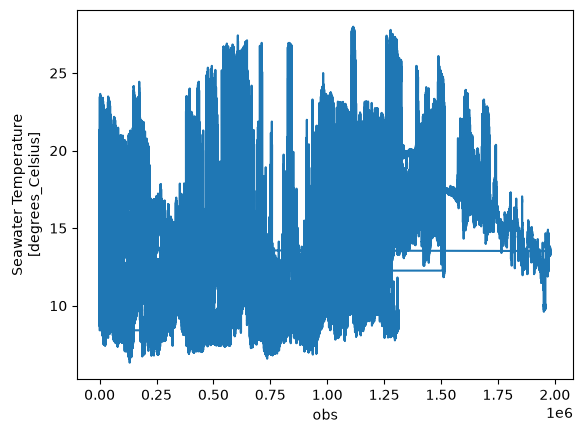

In [11]:
%%time
ds_ooi['sea_water_temperature'].plot()

The OOI data files are indexed using the `obs` dimension, which isn't very helpful.  If we swap that for the `time` dimension we can take advantage of xarray's native plotting and other analysis capabilities.

In [12]:
ds_ooi = ds_ooi.swap_dims({'obs': 'time'})  # Swap the primary dimension

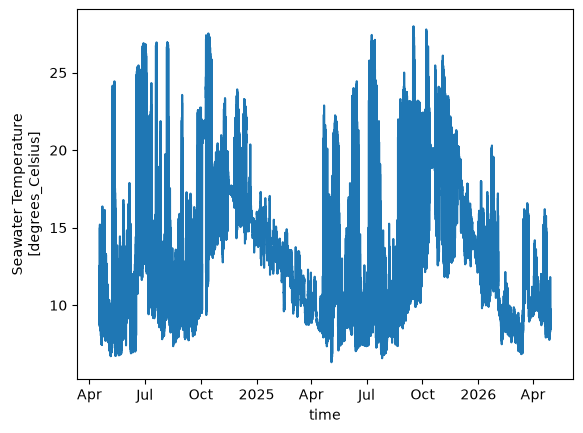

In [13]:
# Let's plot temperature again.
ds_ooi['sea_water_temperature'].plot()

Notice the x-axis now shows actual dates instead of the raw `obs` index, thanks to the `swap_dims` call above.

It's always important to check the quality of the data we're using.

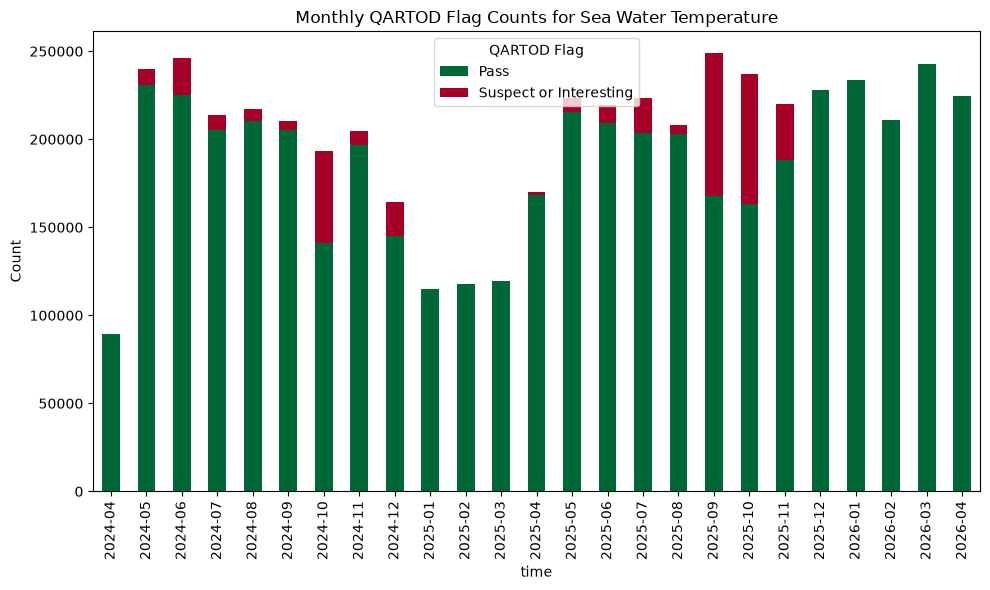

In [14]:
# This is a simple way to look at the QUARTOD flags
# ds_ooi['sea_water_temperature_qartod_executed'].plot(marker='.',linestyle='')

# And here is a more advanced approach
flag_meanings = {1: 'Pass', 2: 'Not Evaluated', 3: 'Suspect or Interesting', 4: 'Fail', 9: 'Missing'}

# QARTOD flags are stored as single-character strings, so cast to int for counting
qartod = ds_ooi['sea_water_temperature_qartod_executed'].compute().to_series().astype(int)

monthly_flag_counts = (
    qartod.groupby([qartod.index.to_period('M'), qartod])
    .size()
    .unstack(fill_value=0)
    .rename(columns=flag_meanings)
)
monthly_flag_counts.index = monthly_flag_counts.index.strftime('%Y-%m')

ax = monthly_flag_counts.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='RdYlGn_r')
ax.set_ylabel('Count')
ax.set_title('Monthly QARTOD Flag Counts for Sea Water Temperature')
ax.legend(title='QARTOD Flag')
plt.tight_layout()
plt.show()

For this dataset, all of the data is flagged 1=good or 3=suspect, but nothing has been outright flagged bad.  So we should be careful when using the suspect data, but it could still be valid, and might have just tripped the rough outlier checks the current OOI data system runs.

### Step 4 - Reuse - Visualization and Analysis

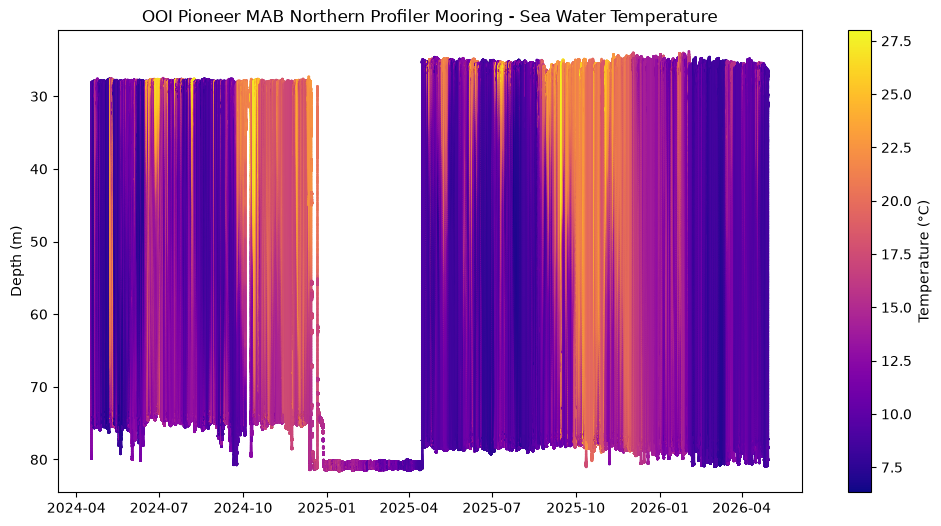

In [16]:
%%time
# Quickplot
# Plotting millions of points is slow. To speed it up, uncomment the second option to plot every 10th point
ds_plot = ds_ooi
# ds_plot = ds_ooi.isel(time=slice(None, None, 10))
fig, ax = plt.subplots(figsize=(12, 6))
cm = ax.scatter(ds_plot['time'], ds_plot['depth'], c=ds_plot['sea_water_temperature'], s=1, cmap='plasma')
ax.invert_yaxis()
ax.set_ylabel('Depth (m)')
ax.set_title('OOI Pioneer MAB Northern Profiler Mooring - Sea Water Temperature')
fig.colorbar(cm, ax=ax, label='Temperature (°C)')
plt.show()

So far we've worked with the full dataset.  It's not huge, but it can take a long time to plot millions of points.  Let's narrow our analysis to just one month. We will also load this subset into memory, since we will use it several times.

In [17]:
ds_ooi_mar2026 = ds_ooi[['sea_water_temperature', 'sea_water_practical_salinity', 'depth', 'lat', 'lon']].sel(time=analysis_period).load()
print(f'{ds_ooi_mar2026.sizes["time"]:,} observations in the analysis period')

242,615 observations in the analysis period


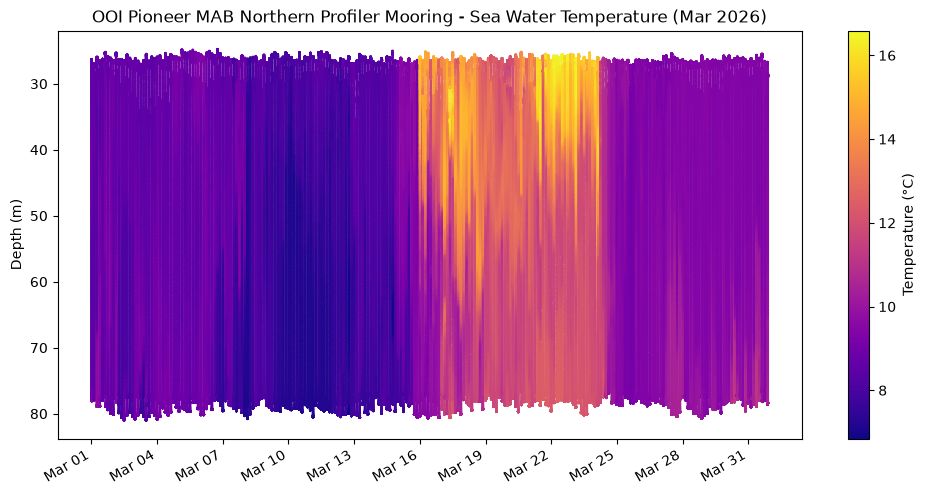

In [18]:
%%time
fig, ax = plt.subplots(figsize=(12, 6))
cm = ax.scatter(ds_ooi_mar2026['time'], ds_ooi_mar2026['depth'], c=ds_ooi_mar2026['sea_water_temperature'], s=1, cmap='plasma')
ax.invert_yaxis()
ax.set_ylabel('Depth (m)')
ax.set_title('OOI Pioneer MAB Northern Profiler Mooring - Sea Water Temperature (Mar 2026)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.autofmt_xdate()
fig.colorbar(cm, ax=ax, label='Temperature (°C)')
plt.show()

There's a lot going on this month.  The water column is pretty cold and well mixed at the beginning of the month, as one might expect during the spring.  However, our profiler only reaches up to 25m so we do not know what is going on at the surface.

We see clearly what might be a Gulf Stream frontal eddy intrusion in the middle of the month, with some variation in the surface mixed layer depths.  And then there is a slight warming in the full water column at the end of the month after the eddy receeds.

To verify this, we could look at satellite or data from other models.

## Part B - ROMS Model Data
For the second part of this study, we will access ROMS Doppio model data from the Rutgers THREDDS data server. A few different products are available, but we will start with the hourly hindcast/forecast data available from the [ROMS Doppio Real-Time Operational PSAS Forecast System Version 1 2017-present](https://tds.marine.rutgers.edu/thredds/catalog/roms/doppio/2017_da/his/catalog.html?dataset=roms/doppio/2017_da/his/History_Best).

Because this model dataset is extremely large, this notebook will carefully subset the data to a single grid point and a specific time period before requesting the actual data.

### Step 1 - Discover - Find relevant ROMS Model data

ROMS Doppio model output is published on the Rutgers THREDDS server, which lets us browse available datasets and open them with `xarray` via OPeNDAP before deciding what (if anything) to download. Here we already know the dataset we want, so we connect directly to its `History_Best` aggregation.

In [19]:
doppio_url = 'https://tds.marine.rutgers.edu/thredds/dodsC/roms/doppio/2017_da/his/History_Best'
ds_roms = xr.open_dataset(doppio_url)
ds_roms

<xarray.Dataset> Size: 3TB
Dimensions:         (time: 79355, tracer: 2, boundary: 4, s_rho: 40, s_w: 41,
                     eta_rho: 106, xi_rho: 242, eta_u: 106, xi_u: 241,
                     eta_v: 105, xi_v: 242, eta_psi: 105, xi_psi: 241,
                     ocean_time: 11)
Coordinates: (12/13)
  * time            (time) datetime64[ns] 635kB 2017-11-02T01:00:00 ... 2026-...
    time_run        (time) datetime64[ns] 635kB ...
  * s_rho           (s_rho) float64 320B -0.9875 -0.9625 ... -0.0375 -0.0125
  * s_w             (s_w) float64 328B -1.0 -0.975 -0.95 ... -0.05 -0.025 0.0
    lon_rho         (eta_rho, xi_rho) float64 205kB ...
    lat_rho         (eta_rho, xi_rho) float64 205kB ...
    ...              ...
    lat_u           (eta_u, xi_u) float64 204kB ...
    lon_v           (eta_v, xi_v) float64 203kB ...
    lat_v           (eta_v, xi_v) float64 203kB ...
    lon_psi         (eta_psi, xi_psi) float64 202kB ...
    lat_psi         (eta_psi, xi_psi) float64 202kB ...
  * ocean_time      (ocean_time) datetime64[ns] 88B 2026-11-21T01:00:00 ... 2...
Dimensions without coordinates: tracer, boundary, eta_rho, xi_rho, eta_u, xi_u,
                                eta_v, xi_v, eta_psi, xi_psi
Data variables: (12/119)
    time_offset     (time) datetime64[ns] 635kB ...
    ntimes          int32 4B ...
    ndtfast         int32 4B ...
    dt              float64 8B ...
    dtfast          float64 8B ...
    dstart          datetime64[ns] 8B ...
    ...              ...
    sustr           (time, eta_u, xi_u) float32 8GB ...
    svstr           (time, eta_v, xi_v) float32 8GB ...
    v_northward_1m  (time, eta_rho, xi_rho) float32 8GB ...
    u_eastward_1m   (time, eta_rho, xi_rho) float32 8GB ...
    Vwind           (time, eta_rho, xi_rho) float32 8GB ...
    Uwind           (time, eta_rho, xi_rho) float32 8GB ...
Attributes: (12/53)
    file:                            doppio_his_7623.nc
    format:                          netCDF-4/HDF5 file
    Conventions:                     CF-1.4, SGRID-0.3
    type:                            ROMS history file
    title:                           ROMS doppio Real-Time Operational PSAS F...
    var_info:                        ../../Data/varinfo.yaml
    ...                              ...
    cdm_data_type:                   GRID
    featureType:                     GRID
    location:                        Proto fmrc:doppio_2017_da_his
    summary:                         doppio
    DODS_EXTRA.Unlimited_Dimension:  ocean_time
    EXTRA_DIMENSION.N:               40

In [20]:
print('\nDataset summary')
print(f'  Size:    {ds_roms.nbytes/1e12:,.3f} TB')

print('Temperature summary')
temp_var = ds_roms['temp']
print(f'  dims:        {temp_var.dims}')
print(f'  shape:       {temp_var.shape}')
print(f'  dtype:       {temp_var.dtype}')
print(f'  n_values:    {temp_var.size:,}')
print(f'  size:        {temp_var.nbytes/1e9:,.1f} GB')
print(f'  attrs:       {temp_var.attrs}')


Dataset summary
  Size:    3.431 TB
Temperature summary
  dims:        ('time', 's_rho', 'eta_rho', 'xi_rho')
  shape:       (79355, 40, 106, 242)
  dtype:       float32
  n_values:    81,424,578,400
  size:        325.7 GB
  attrs:       {'units': 'Celsius', 'long_name': 'potential temperature', 'standard_name': 'sea_water_potential_temperature', 'time': 'ocean_time', 'cell_methods': 'ocean_time: point ocean_time: mean', 'grid': 'grid', 'location': 'face', 'field': 'temperature', '_ChunkSizes': array([  1,  20, 106, 242], dtype=int32)}


The ROMS dataset is very large. Loading a full variable can take a very long time or fail because doing so will run into memory or server limits. So, we need to select only the relevant time range, horizontal grid point, and variables before calling `.load()`.

If we were to make multiple requests to the same dataset, we should also download a local version to save on network and data server processing time.

#### Find the closest grid point to the Mooring
In order to extract the model data at the grid point we need, we need to know the location of the OOI Profiler.  Luckily, the latitude and longitude are included in the dataset. We will use their mean values to represent the mooring location.  (In this case, there is only one value anyway, but some moorings do move around a bit between deployments.)

In [22]:
ooi_lat = float(ds_ooi_mar2026['lat'].mean())
ooi_lon = float(ds_ooi_mar2026['lon'].mean())
print(f'OOI location: lat={ooi_lat:.4f}, lon={ooi_lon:.4f}')

OOI location: lat=36.1798, lon=-74.8267


In [32]:
def haversine_km(lon1, lat1, lon2, lat2):
    """Great-circle distance (km) between two lon/lat points, without an extra geo library."""
    r_earth = 6371.0
    lon1, lat1, lon2, lat2 = np.radians([lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return r_earth * 2 * np.arcsin(np.sqrt(a))

# Find the nearest ROMS grid point (eta/xi indices on the rho grid) to the OOI Profiler
lon2d = ds_roms['lon_rho']
lat2d = ds_roms['lat_rho']
dist2 = (lon2d - ooi_lon) ** 2 + (lat2d - ooi_lat) ** 2
eta_idx, xi_idx = (int(i) for i in np.unravel_index(np.nanargmin(dist2.values), dist2.shape))

xi_idx = 43 # Override the closest point to get a more representative model depth gridpoint

grid_lat = float(lat2d.isel(eta_rho=eta_idx, xi_rho=xi_idx))
grid_lon = float(lon2d.isel(eta_rho=eta_idx, xi_rho=xi_idx))
model_depth = float(ds_roms['h'].isel(eta_rho=eta_idx, xi_rho=xi_idx))

print(f'Nearest grid point: eta={eta_idx}, xi={xi_idx}, lat/lon={grid_lat:.4f}, {grid_lon:.4f}')
print(f'  Model bathymetric depth: {model_depth:.0f} m')
print(f'  Distance to OOI mooring: {haversine_km(ooi_lon, ooi_lat, grid_lon, grid_lat):.2f} km')

Nearest grid point: eta=45, xi=43, lat/lon=36.1591, -74.8580
  Model bathymetric depth: 99 m
  Distance to OOI mooring: 3.64 km


#### ROMS Domain Map
Here is where that point sits in the full ROMS Doppio domain.

*(For some sites the nearest grid point is not the best match, for example at a shelf break where the depth changes quickly. The Appendix shows how to check nearby points.)*

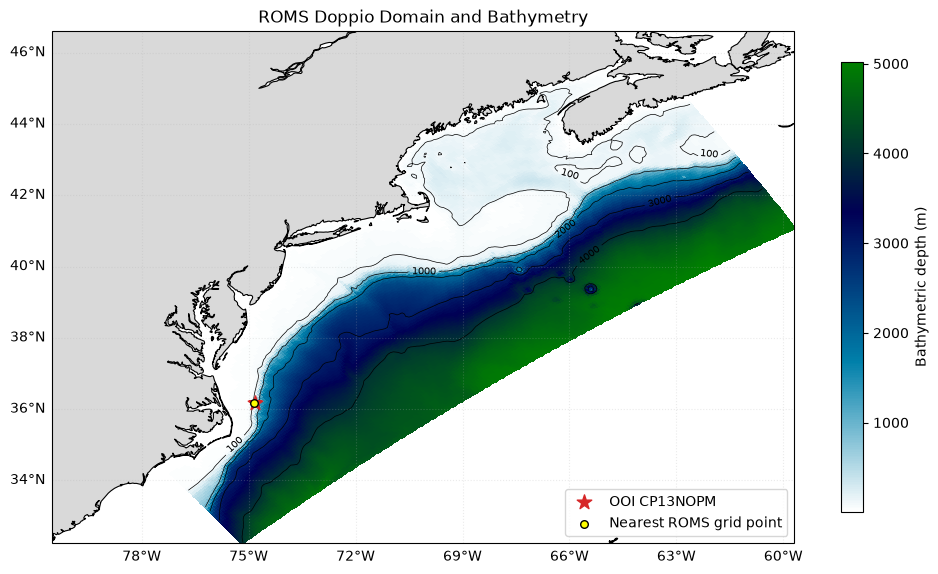

In [33]:
map_crs = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': map_crs})

bathymetry = ds_roms.h.plot.pcolormesh(
    x='lon_rho', y='lat_rho', cmap='ocean_r', ax=ax, transform=map_crs, add_colorbar=False,
)
contours = ds_roms.h.plot.contour(
    x='lon_rho', y='lat_rho', colors='k', levels=[100, 1000, 2000, 3000, 4000],
    linewidths=0.5, ax=ax, transform=map_crs, add_colorbar=False,
)
contours.clabel(fmt='%d', fontsize=7, colors='k', inline=True, inline_spacing=4)

ax.add_feature(cfeature.LAND, facecolor='0.85', edgecolor='none', zorder=2)
ax.coastlines(resolution='10m', color='black', linewidth=0.8, zorder=3)
ax.scatter(ooi_lon, ooi_lat, s=120, c='tab:red', marker='*', label='OOI CP13NOPM', zorder=4, transform=map_crs)
ax.scatter(grid_lon, grid_lat, s=30, c='yellow', edgecolor='k', label='Nearest ROMS grid point', zorder=5, transform=map_crs)

gridlines = ax.gridlines(draw_labels=True, alpha=0.25, linestyle=':')
gridlines.top_labels = False
gridlines.right_labels = False
ax.set_extent([float(lon2d.min()), float(lon2d.max()), float(lat2d.min()), float(lat2d.max())], crs=map_crs)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('ROMS Doppio Domain and Bathymetry')
ax.legend(loc='lower right')
fig.colorbar(bathymetry, ax=ax, label='Bathymetric depth (m)', shrink=0.8)
plt.tight_layout()
plt.show()

### Step 2 - Access (Parse and Load)
Next we can load the ROMS profile time series data we are interested in.

For this example we will load only the March 2026 temperature and salinity profiles at the selected grid point.  We will call `.load()` now which will actually load the dataset into memory.  Because it takes a while for THREDDS to extract this dataset, this line will take a while.  Because THREDDS caches previous requests, this line may actually run faster if you run it again.

In [34]:
%%time
# Load Selected ROMS Profiles
ds_profile_temp = ds_roms['temp'].sel(time=analysis_period, eta_rho=eta_idx, xi_rho=xi_idx).load()
ds_profile_sal = ds_roms['salt'].sel(time=analysis_period, eta_rho=eta_idx, xi_rho=xi_idx).load()

CPU times: user 12.3 ms, sys: 15.3 ms, total: 27.6 ms
Wall time: 8.29 s


In [35]:
print(f'Temp dataset size:        {ds_profile_temp.nbytes/1e6:,.1f} MB')

Temp dataset size:        0.1 MB


### Step 3 - Wrangle (restructure, clean, merge, and quality control)

The only thing we have to do for this dataset is convert the ROMS s-coordinate to a usable depth.  (If we were to use a library like `xroms` it would handle this for us.)

ROMS `s_rho` is a dimensionless vertical coordinate with values from approximately -1 at the bottom to 0 at the surface. ROMS physical depth also depends on bathymetry, sea-surface height, stretching parameters, and `Vtransform`, so it must be calculated rather than estimated as `s_rho * h`.

ROMS supports two `Vtransform` conventions for combining these terms: `Vtransform=1` ([Song and Haidvogel, 1994](https://doi.org/10.1006/jcph.1994.1088)) computes a resting-depth-referenced `z0` and then stretches it for the free surface, while `Vtransform=2` ([Shchepetkin and McWilliams, 2005](https://doi.org/10.1016/j.ocemod.2004.08.002)) computes a fractional depth between 0 and 1 and scales the full water column (`h + zeta`) by it. The Doppio dataset reports which convention it uses via the `Vtransform` variable, so the code below branches on that value rather than assuming one formula.

The conversion combines four pieces at our selected grid point:

- `h`: the time-invariant bathymetric (resting) depth
- `Cs_r`: the stretching-curve values that shape how sigma levels bunch up near the surface or the seafloor
- `zeta`: the sea-surface height anomaly, which raises/lowers every sigma level as it changes in time
- `hc`: a critical depth parameter that controls how sigma levels are distributed between shallow and deep water

In [36]:
# Same point and time range as ds_profile_temp
zeta_pt = ds_roms['zeta'].sel(time=analysis_period, eta_rho=eta_idx, xi_rho=xi_idx)

h_pt = ds_roms['h'].isel(eta_rho=eta_idx, xi_rho=xi_idx)
hc = ds_roms['hc']
s_rho = ds_roms['s_rho']
Cs_r = ds_roms['Cs_r']
Vtransform = int(ds_roms['Vtransform'])

if Vtransform == 1:
    z0 = hc * (s_rho - Cs_r) + h_pt * Cs_r
    z_rho = z0 + zeta_pt * (1 + z0 / h_pt)
elif Vtransform == 2:
    z0 = (hc * s_rho + h_pt * Cs_r) / (hc + h_pt)
    z_rho = zeta_pt + (zeta_pt + h_pt) * z0
else:
    raise ValueError(f'Unsupported Vtransform: {Vtransform}')

# Store depth as positive meters downward for direct comparison with OOI.
ds_profile_temp = ds_profile_temp.assign_coords(depth=(-z_rho).transpose('time', 's_rho'))
ds_profile_sal = ds_profile_sal.assign_coords(depth=(-z_rho).transpose('time', 's_rho'))

#### Vertical context
How do the model levels compare with the part of the water column the profiler samples? The dots below are the average depth of each ROMS level at this grid point, and the shaded band is the depth range of the OOI profiler data (1st to 99th percentile).

OOI profiler depth range: 26 - 80 m | model depth: 99 m | 40 ROMS levels


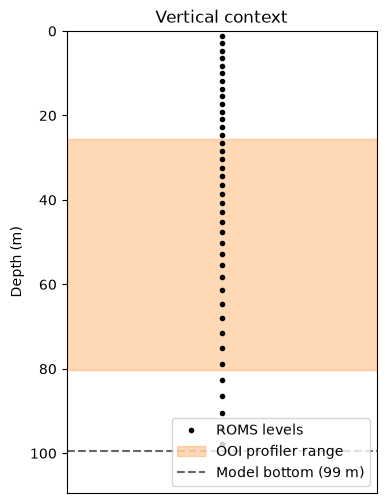

In [37]:
level_depth = (-z_rho).mean('time')
ooi_depth_min, ooi_depth_max = (float(ds_ooi_mar2026['depth'].quantile(q)) for q in (0.01, 0.99))
print(f'OOI profiler depth range: {ooi_depth_min:.0f} - {ooi_depth_max:.0f} m | model depth: {model_depth:.0f} m | {level_depth.size} ROMS levels')

fig, ax = plt.subplots(figsize=(4, 6))
ax.plot(np.zeros(level_depth.size), level_depth, 'k.', label='ROMS levels')
ax.axhspan(ooi_depth_min, ooi_depth_max, color='tab:orange', alpha=0.3, label='OOI profiler range')
ax.axhline(model_depth, color='0.4', ls='--', label=f'Model bottom ({model_depth:.0f} m)')
ax.set_ylim(model_depth + 10, 0)
ax.set_xticks([])
ax.set_ylabel('Depth (m)')
ax.set_title('Vertical context')
ax.legend(loc='lower right')
plt.show()

#### Save a local copy
Since we will want to reuse these subsets (or share them), let's save them as small NetCDF files, so we don't have to request them from the data servers again. The ROMS file includes the `depth` coordinate we just calculated.

In [40]:
ooi_file = 'ooi_cp13nopm_ctd_2026-03.nc'
roms_file = 'doppio_cp13nopm_2026-03.nc'

ds_ooi_mar2026.to_netcdf(ooi_file)
xr.Dataset({'temp': ds_profile_temp, 'salt': ds_profile_sal}).to_netcdf(roms_file)

for f in (ooi_file, roms_file):
    print(f'{f}: {os.path.getsize(f) / 1e6:.1f} MB')

# To reuse them later, no data server request is needed:
# ds_ooi_mar = xr.open_dataset(ooi_file)
# ds_roms_profiles = xr.open_dataset(roms_file)

/tmp/ipykernel_398/251299534.py:4: UserWarning: Unlimited dimension(s) {'obs'} declared in 'dataset.encoding', but not part of current dataset dimensions. Consider removing {'obs'} from 'dataset.encoding'.
  ds_ooi_mar2026.to_netcdf(ooi_file)


ooi_cp13nopm_ctd_2026-03.nc: 11.4 MB
doppio_cp13nopm_2026-03.nc: 0.5 MB


### Step 4 - Reuse - Visualization and Analysis

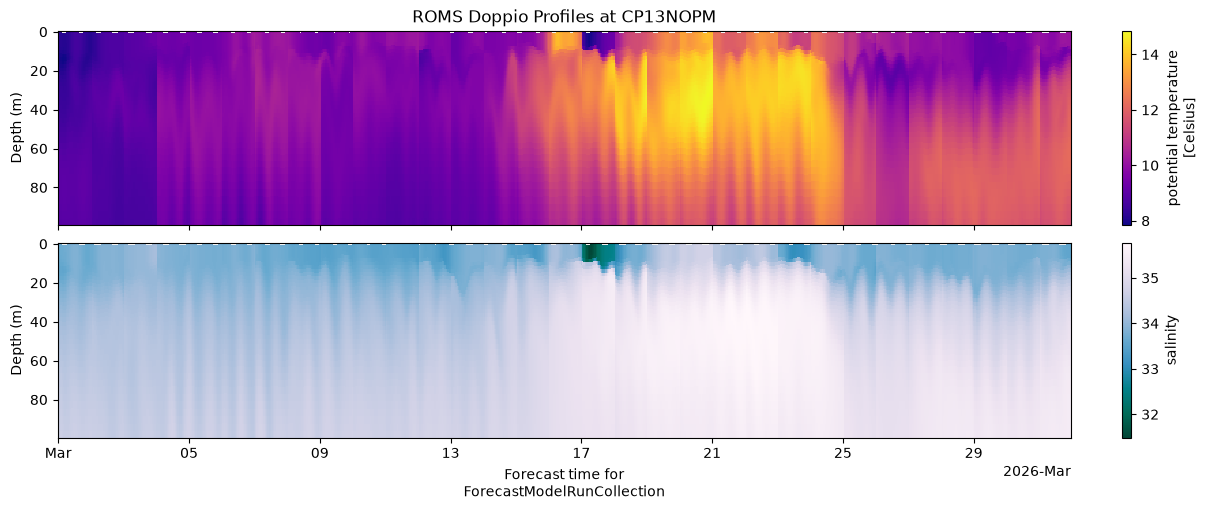

In [41]:
# Quickplot the ROMS profiles
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True)

# We could use either depth or s_rho coordinates for the y-axis
ds_profile_temp.plot(
    x='time', y='depth',
    yincrease=False, ax=axes[0], cmap='plasma',
    vmin=float(ds_profile_temp.min()), vmax=float(ds_profile_temp.max()))
ds_profile_sal.plot(
    x='time', y='depth',
    yincrease=False, ax=axes[1], cmap='PuBuGn_r',
    vmin=float(ds_profile_sal.min()), vmax=float(ds_profile_sal.max()))

axes[0].set_xlabel('')
axes[1].set_title('')
axes[0].set_ylabel('Depth (m)')
axes[1].set_ylabel('Depth (m)')
axes[0].set_title('ROMS Doppio Profiles at CP13NOPM');

## Combined OOI Profiler and ROMS Plot

The ROMS panels show model values on sigma levels converted to time-varying physical depths using bathymetry, sea-surface height, and the ROMS vertical-coordinate parameters.

Finally, let's make a combined plot comparing the two datasets for both temperature and salinity. The ROMS output is plotted as a `pcolormesh`, while the OOI profiler observations are plotted as individual measurements (a `scatter` plot), so there is no need to bin them onto a regular grid. Both use the same color scale.

In [46]:
# Shared color limits for the model and the observations
temp_min = min(float(ds_ooi_mar2026['sea_water_temperature'].min(skipna=True)), float(ds_profile_temp.min(skipna=True)))
temp_max = max(float(ds_ooi_mar2026['sea_water_temperature'].max(skipna=True)), float(ds_profile_temp.max(skipna=True)))
sal_min = min(float(ds_ooi_mar2026['sea_water_practical_salinity'].min(skipna=True)), float(ds_profile_sal.min(skipna=True)))
sal_max = max(float(ds_ooi_mar2026['sea_water_practical_salinity'].max(skipna=True)), float(ds_profile_sal.max(skipna=True)))

# Time limits, and the depth range to show (the profiler measures only part of the water column)
start_time, end_time = pd.Timestamp('2026-03-01'), pd.Timestamp('2026-04-01')
max_depth = ooi_depth_max + 20  # use model_depth instead to show the full water column

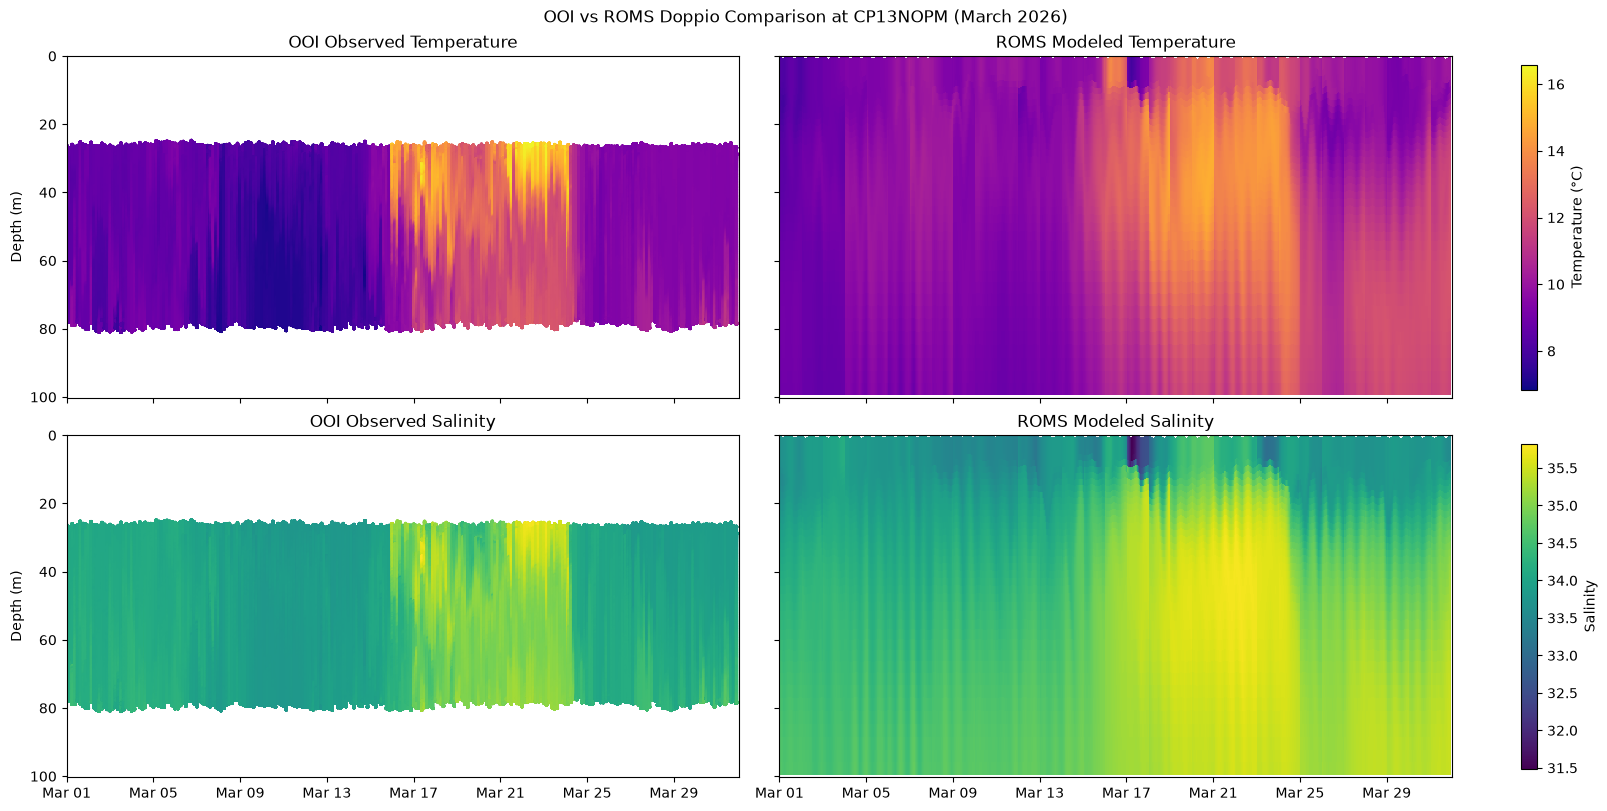

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True, constrained_layout=True)

# Left column: OOI profiler observations (scatter plots)
cm_temp = axes[0, 0].scatter(ds_ooi_mar2026['time'], ds_ooi_mar2026['depth'], c=ds_ooi_mar2026['sea_water_temperature'], s=2, cmap='plasma', vmin=temp_min, vmax=temp_max)
cm_sal = axes[1, 0].scatter(ds_ooi_mar2026['time'], ds_ooi_mar2026['depth'], c=ds_ooi_mar2026['sea_water_practical_salinity'], s=2, cmap='viridis', vmin=sal_min, vmax=sal_max)

# Right column: ROMS Doppio model output (pcolormesh plots)
ds_profile_temp.plot(x='time', y='depth', ax=axes[0, 1], add_colorbar=False, cmap='plasma', vmin=temp_min, vmax=temp_max)
ds_profile_sal.plot(x='time', y='depth', ax=axes[1, 1], add_colorbar=False, cmap='viridis', vmin=sal_min, vmax=sal_max)

axes[0, 0].set_ylim(max_depth, 0)  # the axes are shared, so this sets all four panels
axes[0, 0].set_xlim(start_time, end_time)

for ax in axes.flat:
    ax.set_title('')  # clear any auto-generated xarray coordinate title
    ax.set_xlabel('')

for ax in axes[1, :]:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

fig.suptitle('OOI vs ROMS Doppio Comparison at CP13NOPM (March 2026)')
axes[0, 0].set_title('OOI Observed Temperature')
axes[0, 1].set_title('ROMS Modeled Temperature')
axes[1, 0].set_title('OOI Observed Salinity')
axes[1, 1].set_title('ROMS Modeled Salinity')
axes[0, 0].set_ylabel('Depth (m)')
axes[1, 0].set_ylabel('Depth (m)')
axes[0, 1].set_ylabel('')  # shares y-axis with the left column
axes[1, 1].set_ylabel('')  # shares y-axis with the left column

fig.colorbar(cm_temp, ax=axes[0, :], label='Temperature (°C)', shrink=0.95)
fig.colorbar(cm_sal, ax=axes[1, :], label='Salinity', shrink=0.95)
plt.show()

While these are comparable time-depth views, it's important to remember that these two datasets are two very different representations of the ocean.

## Summary
Here are a few takeaways from the notebook.

### Data Access
* In this notebook we were easily able to download a month of ROMS data to compare with an OOI profiler.
* However, accessing longer timeframes over THREDDS would be more challenging, requiring different strategies.
* Comparing point observations to a regional ocean model can be tricky, as the depth of the "nearest grid point" may change rapidly over just a few grid cells, especially near a shelf break. It can help to review the bathymetry around the site (see the Appendix) and compare it to the actual deployment depth of the mooring.
* This particular dataset does not have a true "depth" variable, so we need to convert `s_rho` levels to physical depth.  (Some model libraries, like xroms may do this automatically.)

### Oceanographic Notes
* Over this time period, the model tends to run a bit warmer than the observed profiler temperatures at the surface and mid depths.  Of course, the profiler is missing much of the surface layer, since it measures the portion of the water column from 25-80m.  In addition, the model depth at this location is about 100m, so comparisons are not straightforward.
* Below the surface, the model also appears to be a touch saltier than the observations, especially during the frontal eddy period in the middle of the month.
* A few features appear to line up between the datasets, including what looks like a Gulf Stream frontal eddy in the middle of the month, though the model has a cold/fresh water surface influx on March 18 (which the profiler can't confirm) and some structural differences in how the features progress.
* The model also has slightly warmer/saltier waers in the bottom layer for the last part of the month compared to the profiler.
* It's not fully clear why there is some disagreement, but here are a few plausible contributors:
  * The shelf-break region here is dynamically active (we're at the shelfbreak front, where Gulf Stream eddies and cross-shelf exchange processes vary a lot, and even a several-kilometer model grid may not resolve the frontal-scale structure the profiler is sampling.
  * Data assimilation and initialization in the ROMS Doppio hindcast could shift the timing or strength of features without necessarily affecting larger scale patterns.  There is very little oceanographic data assimilation in this area.  (The MAB OOI moorings are not yet included.)

## Appendix - Choosing a ROMS Grid Point

The geographically nearest ROMS rho point is not always the best comparison point. If the model bathymetry changes quickly near the site (for example at a shelf break), the nearest point can be in much deeper or shallower water than the mooring. To check, inspect the neighboring `eta` points along the selected `xi` column.

To use a different grid point in this notebook, change `eta_idx` and `xi_idx` in Part B, Step 1 and re-run the cells after it.

In [48]:
# Inspect a window of neighboring eta points on the selected xi column.
xi_line = pd.DataFrame({
    'eta': np.arange(lat2d.shape[0]),
    'latitude': lat2d.isel(xi_rho=xi_idx).values,
    'longitude': lon2d.isel(xi_rho=xi_idx).values,
    'depth_m': ds_roms['h'].isel(xi_rho=xi_idx).values,
    'ocean': ds_roms['mask_rho'].isel(xi_rho=xi_idx).values.astype(bool),
})

eta_window = 10
eta_start = max(0, eta_idx - eta_window)
eta_end = min(lat2d.shape[0], eta_idx + eta_window + 1)
xi_line_nearby = xi_line.iloc[eta_start:eta_end].copy()

display(xi_line_nearby)

,eta,latitude,longitude,depth_m,ocean
35,35,35.672663,-74.362377,2363.000308,True
36,36,35.721396,-74.411667,2174.125898,True
37,37,35.770109,-74.461016,1972.562612,True
38,38,35.818802,-74.510425,1851.883876,True
39,39,35.867474,-74.559893,1860.259715,True
40,40,35.916126,-74.609422,1755.211575,True
41,41,35.964757,-74.659010,1466.490965,True
42,42,36.013368,-74.708658,1031.669834,True
43,43,36.061958,-74.758367,506.170208,True
44,44,36.110527,-74.808135,217.037474,True


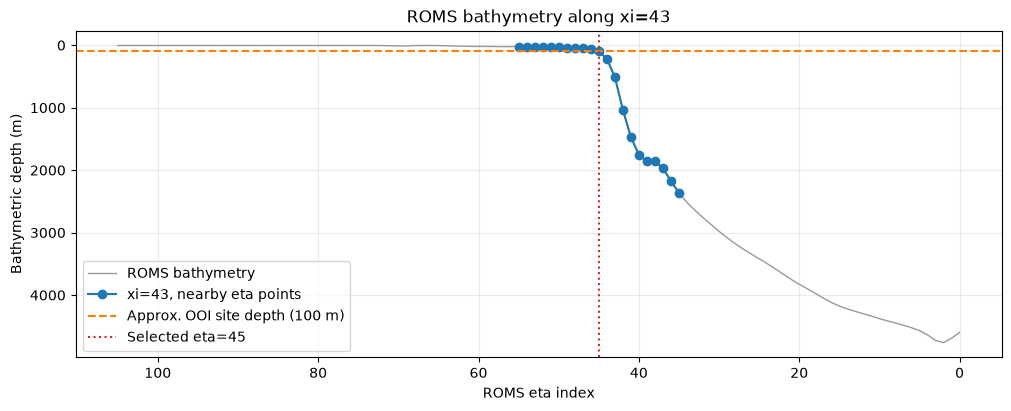

In [49]:
ooi_site_depth = 100  # Approximate water depth (m) at the mooring. Update this for your site.

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(xi_line['eta'], xi_line['depth_m'], color='0.6', lw=1, label='ROMS bathymetry')
ax.plot(xi_line_nearby['eta'], xi_line_nearby['depth_m'], 'o-', color='tab:blue', label=f'xi={xi_idx}, nearby eta points')
ax.axhline(ooi_site_depth, color='tab:orange', ls='--', label=f'Approx. OOI site depth ({ooi_site_depth} m)')
ax.axvline(eta_idx, color='tab:red', ls=':', label=f'Selected eta={eta_idx}')

ax.invert_xaxis()  # flip the x-axis
ax.set_xlabel('ROMS eta index')
ax.set_ylabel('Bathymetric depth (m)')
ax.set_title(f'ROMS bathymetry along xi={xi_idx}')
ax.invert_yaxis()
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()

#### ROMS Grid Map
This map shows the full ROMS grid (every 20th grid line), with the grid corners and the selected point labeled.

**Try it yourself:** change `eta_idx` in Part B, Step 1 and re-run to see how a different grid point (and its distance/depth mismatch with the mooring) affects the comparison.

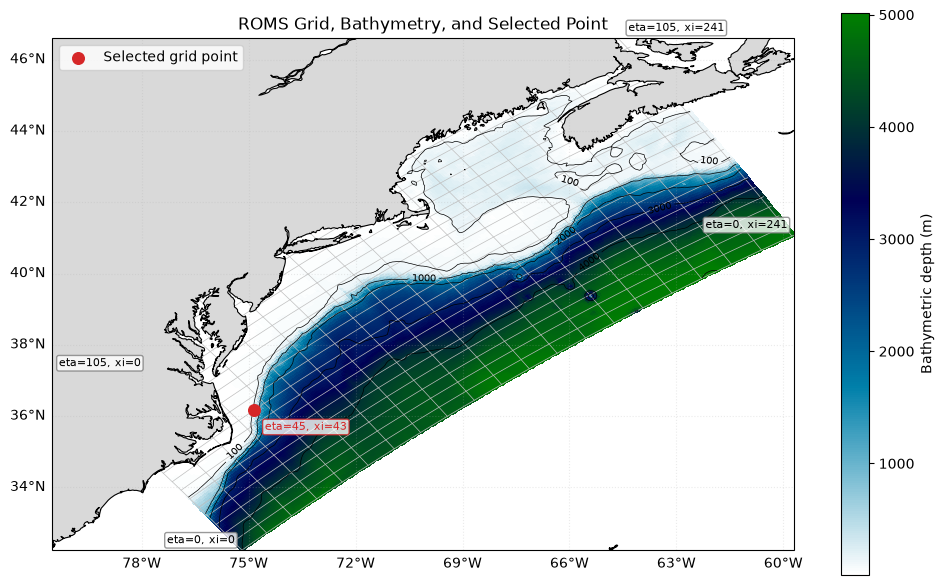

In [50]:
# ROMS domain map with the grid, coastlines and the selected point.
map_crs = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': map_crs})

# Subsample grid lines to keep plotting light and readable.
step_eta = max(1, lat2d.shape[0] // 20)
step_xi = max(1, lat2d.shape[1] // 20)

for eta in range(0, lat2d.shape[0], step_eta):
    ax.plot(lon2d.isel(eta_rho=eta), lat2d.isel(eta_rho=eta), color='0.75', lw=0.5, transform=map_crs)
for xi in range(0, lon2d.shape[1], step_xi):
    ax.plot(lon2d.isel(xi_rho=xi), lat2d.isel(xi_rho=xi), color='0.75', lw=0.5, transform=map_crs)

bathymetry = ds_roms.h.plot.pcolormesh(
    x='lon_rho', y='lat_rho', cmap='ocean_r', ax=ax, transform=map_crs, add_colorbar=False,
)
contours = ds_roms.h.plot.contour(
    x='lon_rho', y='lat_rho', colors='k', levels=[100, 1000, 2000, 3000, 4000, 5000],
    linewidths=0.5, ax=ax, transform=map_crs, add_colorbar=False,
)
contours.clabel(fmt='%d', fontsize=7, colors='k', inline=True, inline_spacing=4)

ax.add_feature(cfeature.LAND, facecolor='0.85', edgecolor='none', zorder=2)
ax.coastlines(resolution='10m', color='black', linewidth=0.8, zorder=3)
ax.scatter(grid_lon, grid_lat, s=70, c='tab:red', marker='o', label='Selected grid point', zorder=4, transform=map_crs)

# Label the four grid corners and the selected grid point.
corner_indices = [
    (0, 0),
    (0, lon2d.shape[1] - 1),
    (lat2d.shape[0] - 1, 0),
    (lat2d.shape[0] - 1, lon2d.shape[1] - 1),
]
for corner_eta, corner_xi in corner_indices:
    corner_lon = float(lon2d.isel(eta_rho=corner_eta, xi_rho=corner_xi).values)
    corner_lat = float(lat2d.isel(eta_rho=corner_eta, xi_rho=corner_xi).values)
    is_top_corner = corner_eta == 0
    ax.annotate(
        f'eta={corner_eta}, xi={corner_xi}',
        xy=(corner_lon, corner_lat),
        xytext=(-5 if is_top_corner else 5, 5),
        textcoords='offset points',
        fontsize=8,
        ha='right' if is_top_corner else 'left',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8, ec='0.5'),
        zorder=5,
        xycoords=map_crs._as_mpl_transform(ax),
    )

ax.annotate(
    f'eta={eta_idx}, xi={xi_idx}',
    xy=(grid_lon, grid_lat),
    xytext=(8, -14),
    textcoords='offset points',
    fontsize=8,
    color='tab:red',
    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8, ec='tab:red'),
    zorder=5,
    xycoords=map_crs._as_mpl_transform(ax),
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('ROMS Grid, Bathymetry, and Selected Point')
ax.legend(loc='best')
gridlines = ax.gridlines(draw_labels=True, alpha=0.25, linestyle=':')
gridlines.top_labels = False
gridlines.right_labels = False
ax.set_extent([float(lon2d.min()), float(lon2d.max()), float(lat2d.min()), float(lat2d.max())], crs=map_crs)
fig.colorbar(bathymetry, ax=ax, label='Bathymetric depth (m)')
plt.tight_layout()
plt.show()